# LENDING CLUB

# OTIMIZAÇÃO DA CARTEIRA DE CRÉDITO

Este notebook constitui a **segunda etapa** da abordagem *predict-then-optimize*. Na primeira etapa (notebook 03), um modelo de scorecard estimou a probabilidade de default (PD) de cada solicitante e filtrou os 33.332 clientes elegíveis. Agora, de posse dessas estimativas, resolvemos o problema de decisão que é o cerne da Pesquisa Operacional: dado um capital limitado, **a quais clientes elegíveis conceder crédito** de modo a maximizar o retorno esperado da carteira, respeitando limites de capital e de diversificação.

Trata-se de um problema de **programação linear inteira binária** (0-1): para cada contrato decide-se, de forma discreta, conceder ou não o empréstimo. A estrutura é a de um *knapsack* multidimensional, em que o capital é o recurso escasso e cada empréstimo compete por ele com base na sua contribuição ao lucro e no seu consumo de capital.

# 1. IMPORTANDO BIBLIOTECAS

A otimização usa a biblioteca PuLP com o solver CBC. A célula abaixo garante a versão 2.x do PuLP — a 4.x mudou a API e não traz solver embutido. Se o PuLP já tiver sido carregado em outra versão nesta sessão, reinicie o kernel e execute novamente a partir daqui.

In [20]:
# --- Preparação do ambiente: garante PuLP 2.x (API clássica + solver CBC) ---
import subprocess, sys

def _pulp_classico():
    try:
        import pulp
        return hasattr(pulp, 'PULP_CBC_CMD') and hasattr(pulp.LpVariable, 'dicts')
    except Exception:
        return False

if not _pulp_classico():
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pulp==2.8.0'], check=False)
    for _m in [k for k in list(sys.modules) if k == 'pulp' or k.startswith('pulp.')]:
        del sys.modules[_m]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pulp

pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
plt.rcParams['figure.figsize'] = (10, 5)
print('PuLP', pulp.__version__)

PuLP 2.8.0


# 2. CONJUNTO DE DADOS

Carregamos a base de clientes elegíveis exportada pelo notebook 03. Cada linha é um contrato candidato, identificado por `id_cliente`, com o valor e as condições do empréstimo, a classificação de risco (`grade`), a finalidade (`purpose`) e, sobretudo, a probabilidade de default (`PD`) estimada pelo modelo.

In [21]:
clientes = pd.read_parquet('dados/clientes_elegiveis.parquet')
print(f'Contratos elegíveis: {len(clientes):,}')
print(f'id_cliente único? {clientes["id_cliente"].is_unique}')
clientes.head()

Contratos elegíveis: 33,332
id_cliente único? True


,id_cliente,loan_amnt,int_rate,term,installment,grade,purpose,annual_inc,PD,score,default
0,237325,12025,16.99,60,298.79,D,debt_consolidation,"154,000.00",0.20,492.06,0
1,237327,10000,12.85,36,336.22,B,debt_consolidation,"65,000.00",0.12,523.24,1
2,237328,30000,14.98,60,713.39,C,credit_card,"147,000.00",0.14,515.35,0
3,237333,16000,11.99,36,531.36,B,debt_consolidation,"85,000.00",0.14,517.20,0
4,237344,6000,12.85,36,201.74,B,credit_card,"21,000.00",0.19,494.88,1


# 3. RETORNO E PERDA ESPERADA

Para otimizar a carteira é preciso traduzir cada contrato em uma contribuição monetária esperada. Definimos três quantidades por empréstimo $i$:

1. **Juros totais contratados** ($j_i$), o que a instituição recebe além do principal caso o empréstimo seja integralmente honrado. A parcela mensal (`installment`) é fixada no contrato no momento da originação e pode ser reconstruída exatamente pela fórmula de amortização a partir de `loan_amnt`, `int_rate` e `term`; é, portanto, informação disponível na hora da decisão de conceder ou não, e não um valor realizado depois. O total que o tomador se compromete a pagar, se cumprir o contrato até o fim, é $\text{installment}_i \times \text{term}_i$, e os juros totais contratados são esse valor menos o principal $v_i$ (`loan_amnt`):

$$j_i = \text{installment}_i \times \text{term}_i - v_i$$

2. **Perda em caso de default**, modelada como $\text{LGD} \times v_i$, em que LGD (*Loss Given Default*) é a fração do principal perdida. Adotamos $\text{LGD} = 1$, hipótese conservadora que supõe a perda integral do principal e ignora pagamentos feitos antes do default e eventuais recuperações. O valor é um parâmetro e pode ser ajustado.

3. **Lucro esperado** ($\ell_i$), que pondera os dois cenários pela probabilidade de default estimada:

$$\ell_i = (1 - PD_i)\, j_i - PD_i \cdot \text{LGD} \cdot v_i$$

É $\ell_i$ que o modelo busca maximizar. Note que ele já incorpora o risco estimado na primeira etapa: dois empréstimos de mesmo valor e mesma taxa têm lucros esperados diferentes se seus PD diferem.

In [22]:
LGD = 1.0   # perda dado o default (fração do principal); 1.0 = perda integral

# 'installment' é a parcela contratual? Reconstruímos pela fórmula de amortização
# (Price) a partir de loan_amnt, int_rate e term — grandezas definidas na originação.
r = clientes['int_rate'] / 100 / 12
n = clientes['term']
parcela_contratual = clientes['loan_amnt'] * r * (1 + r)**n / ((1 + r)**n - 1)
dif = (clientes['installment'] - parcela_contratual).abs()
print(f'installment vs parcela da fórmula de amortização: '
      f'diferença mediana R$ {dif.median():.2f}; {(dif < 1).mean():.1%} dos contratos com diferença < R$ 1.')
print('Confirma que installment é a parcela contratual, fixada na originação (disponível na decisão),')
print('e não um valor realizado após a concessão.\n')

# Juros totais contratados e lucro esperado
clientes['juros'] = clientes['installment'] * clientes['term'] - clientes['loan_amnt']
clientes['lucro_esp'] = (1 - clientes['PD']) * clientes['juros'] - clientes['PD'] * LGD * clientes['loan_amnt']

print(f"Demanda total de capital:       R$ {clientes['loan_amnt'].sum():,.0f}")
print(f"Juros totais contratados:       R$ {clientes['juros'].sum():,.0f}")
print(f"Lucro esperado agregado:        R$ {clientes['lucro_esp'].sum():,.0f}")
print(f"Contratos com lucro esperado positivo: {(clientes['lucro_esp'] > 0).mean():.1%}")
clientes[['loan_amnt', 'int_rate', 'PD', 'juros', 'lucro_esp']].describe().round(2)

installment vs parcela da fórmula de amortização: diferença mediana R$ 0.00; 100.0% dos contratos com diferença < R$ 1.
Confirma que installment é a parcela contratual, fixada na originação (disponível na decisão),
e não um valor realizado após a concessão.

Demanda total de capital:       R$ 449,020,550
Juros totais contratados:       R$ 95,105,433
Lucro esperado agregado:        R$ 26,547,958
Contratos com lucro esperado positivo: 82.6%


,loan_amnt,int_rate,PD,juros,lucro_esp
count,"33,332.00","33,332.00","33,332.00","33,332.00","33,332.00"
mean,"13,471.16",11.13,0.12,"2,853.28",796.47
std,"7,958.75",2.90,0.05,"2,618.32","1,330.23"
min,"1,000.00",6.00,0.03,95.12,"-2,502.61"
25%,"7,500.00",8.90,0.09,"1,238.64",91.25
50%,"12,000.00",11.44,0.13,"1,993.32",386.38
75%,"18,000.00",12.99,0.16,"3,426.00",972.34
max,"35,000.00",25.89,0.20,"24,079.60","12,930.85"


Nesta base, 82,6% dos contratos elegíveis têm lucro esperado positivo, e os cerca de 17% restantes, com lucro esperado negativo, são descartados pelo próprio objetivo — ligá-los apenas subtrairia do total a maximizar. Entre os de lucro positivo, porém, há muito mais demanda do que capital, e é isso que torna o problema não trivial: **sem a restrição de orçamento, a solução concederia crédito a quase todos os contratos lucrativos**. É o capital escasso que obriga a escolher quais deles entram, transformando a decisão num problema de alocação.

# 4. FORMULAÇÃO DO MODELO

Antes da notação matemática, a ideia em linguagem simples. Para cada um dos 33.332 contratos há uma decisão de **tudo ou nada**: concede-se o empréstimo pelo valor integral solicitado ou recusa-se, sem financiar apenas uma parte. O modelo escolhe quais conceder para **obter o maior lucro esperado possível**, obedecendo a quatro regras que um gestor de crédito imporia.

1. **Não gastar mais do que o caixa disponível.** O total emprestado não passa do orçamento de capital (aqui, 80% da demanda).
2. **Não deixar capital ocioso.** O total emprestado tem de atingir ao menos uma fração mínima do orçamento (aqui, 60%), para que o capital captado seja de fato aplicado.
3. **Não concentrar demais em uma finalidade.** A fatia de cada `purpose` (consolidação de dívida, cartão de crédito, etc.) não passa de um teto da **carteira efetivamente montada** — por exemplo, no máximo 45% do que for emprestado pode ir para consolidação de dívida.
4. **Decisão tudo ou nada.** Cada empréstimo é concedido integralmente ou recusado; não há meio-empréstimo.

O risco de crédito não entra como uma regra à parte. Ele já foi tratado em duas frentes: na elegibilidade, que admitiu apenas contratos com PD ≤ 20%, e no próprio lucro esperado $\ell_i$, que penaliza cada contrato pela sua probabilidade de default. Diferente da diversificação, que é uma política de carteira, o risco já está embutido no que cada empréstimo contribui ao objetivo.

A seguir, as mesmas regras em notação formal.

**Conjuntos.** $C$ é o conjunto dos contratos elegíveis; $P$, o das finalidades.

**Variável de decisão.** Para cada contrato $i \in C$:

$$x_i = \begin{cases} 1, & \text{concede o empréstimo } i \text{ pelo valor integral} \\ 0, & \text{recusa} \end{cases}$$

**Parâmetros.** $v_i$ (valor) e $\ell_i$ (lucro esperado) de cada contrato; $B$ (orçamento de capital); $u$ (utilização mínima); $\kappa_p$ (teto de concentração de cada finalidade).

**Função objetivo** — obter o maior lucro esperado:

$$\max \; \sum_{i \in C} \ell_i \, x_i$$

**Restrições.**

$$\textbf{(1) Orçamento máximo:}\quad \sum_{i \in C} v_i \, x_i \;\le\; B$$

$$\textbf{(2) Utilização mínima:}\quad \sum_{i \in C} v_i \, x_i \;\ge\; u \, B$$

$$\textbf{(3) Diversificação por finalidade:}\quad \sum_{i \in p} v_i \, x_i \;\le\; \kappa_p \sum_{j \in C} v_j \, x_j \quad \forall\, p \in P$$

$$\textbf{(4) Decisão tudo ou nada:}\quad x_i \in \{0, 1\} \quad \forall\, i \in C$$

A regra (3) merece atenção: o teto de cada finalidade é uma fração da **carteira montada** $\sum_{j} v_j x_j$, e não do orçamento fixo $B$. A diversificação passa a ser medida sobre o que de fato foi emprestado, de modo que, se a carteira encolhe, os limites de concentração acompanham. O preço dessa escolha é que o lado direito deixa de ser constante e passa a depender da própria decisão, acoplando todas as variáveis; ainda assim a desigualdade é linear, bastando reescrevê-la como $\sum_{i \in p} v_i x_i - \kappa_p \sum_{j} v_j x_j \le 0$.

# 5. PARÂMETROS DO MODELO

Os parâmetros abaixo definem a política de crédito:

1. **Orçamento máximo** de 80% da demanda total;
2. **Utilização mínima** de 60% do orçamento, para não deixar capital ocioso;
3. **Diversificação por finalidade**, com um teto de participação para cada `purpose` sobre a carteira montada. O teto que de fato restringe é o de `debt_consolidation` (45%), que responde por 57% da demanda; `credit_card` (35%) e `home_improvement` (15%) atuam como guarda-corpos, e as demais finalidades recebem um teto comum de 5%.

In [23]:
ORCAMENTO_FRAC = 0.80     # orçamento máximo = 80% da demanda total
UTIL_MIN       = 0.60     # utilização mínima = 60% do orçamento

# Teto de participação por finalidade, como fração da CARTEIRA MONTADA
CAP_PURPOSE = {
    'debt_consolidation': 0.45,
    'credit_card':        0.35,
    'home_improvement':   0.15,
}
CAP_PURPOSE_DEFAULT = 0.05   # teto comum para as demais finalidades

B = ORCAMENTO_FRAC * clientes['loan_amnt'].sum()
print(f'Orçamento máximo (B):         R$ {B:,.0f}')
print(f'Utilização mínima (60% de B): R$ {UTIL_MIN*B:,.0f}')

Orçamento máximo (B):         R$ 359,216,440
Utilização mínima (60% de B): R$ 215,529,864


# 6. CONSTRUÇÃO E SOLUÇÃO DO MODELO

Construímos o modelo com a biblioteca `PuLP` e o resolvemos com o *solver* CBC. São 33.332 variáveis binárias e 15 restrições lineares (orçamento máximo e mínimo e treze de finalidade). Adotamos uma tolerância de *gap* relativo de 1%, prática usual que interrompe a busca quando a solução está comprovadamente a menos de 1% do ótimo, garantindo tempo de resolução baixo sem perda prática de qualidade.

In [24]:
idx = clientes.index
v = clientes['loan_amnt'].to_dict()
l = clientes['lucro_esp'].to_dict()

modelo = pulp.LpProblem('otimizacao_carteira', pulp.LpMaximize)
x = pulp.LpVariable.dicts('x', idx, cat='Binary')   # binária => decisão tudo ou nada

# Objetivo: maximizar o lucro esperado total
modelo += pulp.lpSum(l[i] * x[i] for i in idx), 'lucro_esperado'

# (1) Orçamento máximo
modelo += pulp.lpSum(v[i] * x[i] for i in idx) <= B, 'orcamento_max'

# (2) Utilização mínima do orçamento
modelo += pulp.lpSum(v[i] * x[i] for i in idx) >= UTIL_MIN * B, 'utilizacao_min'

# (3) Diversificação por finalidade, como % da CARTEIRA MONTADA:
#     sum_{i in p} v_i x_i <= kappa_p * sum_j v_j x_j
#     reescrita linear: sum_i (coef_i) v_i x_i <= 0, com coef = (1-k) se i em p, senao -k
for p in sorted(clientes['purpose'].unique()):
    ip = set(clientes.index[clientes['purpose'] == p])
    k = CAP_PURPOSE.get(p, CAP_PURPOSE_DEFAULT)
    modelo += pulp.lpSum(((1 - k) if i in ip else -k) * v[i] * x[i] for i in idx) <= 0, f'purpose_{p}'

print(f'Variáveis: {len(x):,} | Restrições: {len(modelo.constraints)}')
modelo.solve(pulp.PULP_CBC_CMD(msg=0, timeLimit=600, gapRel=0.01))
print(f'Status: {pulp.LpStatus[modelo.status]}')
print(f'Lucro esperado ótimo: R$ {pulp.value(modelo.objective):,.0f}')

Variáveis: 33,332 | Restrições: 15
Status: Optimal
Lucro esperado ótimo: R$ 26,585,405


Status: Optimal
Lucro esperado ótimo: R$ 26,585,403


# 7. A CARTEIRA ÓTIMA

Extraímos a solução: os contratos com $x_i = 1$ compõem a carteira selecionada. Comparamos seus indicadores com os da base elegível completa para dimensionar a decisão.

In [25]:
clientes['selecionado'] = [int(round(x[i].value() or 0)) for i in idx]
carteira = clientes[clientes['selecionado'] == 1]

cap_sel = carteira['loan_amnt'].sum()
pd_pond = (carteira['PD'] * carteira['loan_amnt']).sum() / cap_sel
retorno_pct = carteira['lucro_esp'].sum() / cap_sel

print(f"Contratos selecionados: {len(carteira):,} de {len(clientes):,} ({len(carteira)/len(clientes):.1%})")
print(f"Capital alocado:        R$ {cap_sel:,.0f} ({cap_sel/B:.1%} do orçamento; {cap_sel/clientes['loan_amnt'].sum():.1%} da demanda)")
print(f"Lucro esperado:         R$ {carteira['lucro_esp'].sum():,.0f}")
print(f"Retorno esperado sobre o capital alocado: {retorno_pct:.2%}")
print(f"PD médio ponderado da carteira:       {pd_pond:.2%}")
print(f"PD médio ponderado da base elegível:  {(clientes['PD']*clientes['loan_amnt']).sum()/clientes['loan_amnt'].sum():.2%}")

Contratos selecionados: 21,847 de 33,332 (65.5%)
Capital alocado:        R$ 304,996,075 (84.9% do orçamento; 67.9% da demanda)
Lucro esperado:         R$ 26,585,405
Retorno esperado sobre o capital alocado: 8.72%
PD médio ponderado da carteira:       11.24%
PD médio ponderado da base elegível:  12.37%


# 8. QUAIS REGRAS LIMITARAM A CARTEIRA?

Nem todas as restrições apertam ao mesmo tempo. Uma restrição está **ativa** quando a carteira a atinge no limite; é ela que, na prática, impede o modelo de lucrar mais. Saber quais estão ativas diz ao gestor exatamente onde está o gargalo.

A tabela abaixo mostra, para cada teto de finalidade, quanto a carteira usou e quanto era permitido — ambos medidos sobre a carteira montada. Em seguida, a partir da relaxação linear do problema, estimamos o **valor marginal do capital**: quanto de lucro esperado um real a mais no orçamento adicionaria.

In [26]:
# Corredor de utilização do orçamento
print(f"Capital alocado: R$ {cap_sel:,.0f}")
print(f"  corredor permitido: de R$ {UTIL_MIN*B:,.0f} (mínimo) a R$ {B:,.0f} (máximo)\n")

# Quanto cada teto de finalidade permitia (sobre a carteira montada) e quanto a carteira usou
limites = []
for p in sorted(clientes['purpose'].unique()):
    usado_p = carteira.loc[carteira['purpose'] == p, 'loan_amnt'].sum()
    cap_p = CAP_PURPOSE.get(p, CAP_PURPOSE_DEFAULT)
    teto_p = cap_p * cap_sel          # teto = fração da carteira montada
    limites.append([f'finalidade {p}', usado_p, teto_p, cap_p])

tab = pd.DataFrame(limites, columns=['limite', 'usado', 'teto', 'cap'])
tab['uso_%'] = tab['usado'] / tab['teto'] * 100
tab['ativa'] = np.where(tab['uso_%'] >= 99.0, 'ATIVA', '')
tab = tab.sort_values('uso_%', ascending=False)
saida = tab.assign(usado=tab['usado'].map('R$ {:,.0f}'.format),
                   teto=tab['teto'].map('R$ {:,.0f}'.format),
                   cap=(tab['cap'] * 100).map('{:.0f}%'.format),
                   **{'uso_%': tab['uso_%'].map('{:.1f}%'.format)})
print(saida[['limite', 'usado', 'teto', 'cap', 'uso_%', 'ativa']].to_string(index=False))

# Valor marginal do capital: preço-sombra do orçamento na relaxação linear
relax = modelo.copy()
for var in relax.variables():
    var.cat = 'Continuous'
relax.solve(pulp.PULP_CBC_CMD(msg=0))
for cname, rotulo in [('orcamento_max', 'orçamento máximo'), ('utilizacao_min', 'utilização mínima')]:
    pi = relax.constraints[cname].pi
    pi = 0.0 if abs(pi) < 1e-9 else pi
    print(f"\nPreço-sombra ({rotulo}): R$ {pi:.4f} por R$ 1")

Capital alocado: R$ 304,996,075
  corredor permitido: de R$ 215,529,864 (mínimo) a R$ 359,216,440 (máximo)

                       limite          usado           teto cap  uso_% ativa
finalidade debt_consolidation R$ 137,248,175 R$ 137,248,234 45% 100.0% ATIVA
       finalidade credit_card R$ 106,748,350 R$ 106,748,626 35% 100.0% ATIVA
  finalidade home_improvement  R$ 32,839,850  R$ 45,749,411 15%  71.8%      
             finalidade other   R$ 8,763,450  R$ 15,249,804  5%  57.5%      
    finalidade major_purchase   R$ 8,497,600  R$ 15,249,804  5%  55.7%      
               finalidade car   R$ 3,590,475  R$ 15,249,804  5%  23.5%      
           finalidade medical   R$ 2,602,450  R$ 15,249,804  5%  17.1%      
    finalidade small_business   R$ 1,257,625  R$ 15,249,804  5%   8.2%      
          finalidade vacation   R$ 1,169,800  R$ 15,249,804  5%   7.7%      
             finalidade house   R$ 1,104,200  R$ 15,249,804  5%   7.2%      
            finalidade moving   R$ 1,008,225 


Preço-sombra (orçamento máximo): R$ 0.0000 por R$ 1

Preço-sombra (utilização mínima): R$ 0.0000 por R$ 1


A análise revela os gargalos. Estão ativos **dois tetos de finalidade**: o de `debt_consolidation`, no máximo permitido de 45% da carteira, e o de `credit_card`, nos 35%. São essas duas restrições de concentração que impedem o modelo de lucrar mais — ele gostaria de alocar ainda mais capital justamente nessas finalidades, as mais rentáveis e de maior demanda, mas a política de diversificação não deixa.

O capital **não** é o fator limitante. A carteira alocou R$ 305 mi, dentro do corredor permitido (entre R$ 216 mi e R$ 359 mi) e sem encostar no teto de orçamento — usa apenas 84,9% dele. Por isso o **valor marginal do capital é zero**: injetar mais dinheiro não aumentaria o lucro, porque o que trava a carteira é a diversificação por finalidade, não a disponibilidade de recursos. O modelo sequer consegue usar todo o orçamento, já que preencher o restante exigiria romper os tetos de concentração. Para lucrar mais, o caminho seria rever esses tetos — uma decisão de política, não de caixa. Esse é um resultado típico e valioso da Pesquisa Operacional: além de apontar a melhor decisão, o modelo revela qual restrição é o verdadeiro gargalo.

# 9. COMPARAÇÃO COM POLÍTICAS ALTERNATIVAS

O valor da otimização só fica evidente quando comparada a políticas mais simples, sujeitas ao **mesmo orçamento**. Consideramos duas alternativas ingênuas:

1. **Maior lucro primeiro**: ordena os contratos por densidade de lucro (lucro esperado por real emprestado) e concede crédito até esgotar o orçamento, ignorando a diversificação;
2. **Menor risco primeiro**: ordena por PD crescente e concede até esgotar o orçamento, uma política excessivamente conservadora.

Diferente das duas, a carteira ótima é obrigada a respeitar os tetos de concentração por finalidade. A comparação a seguir mostra o efeito disso — e pede leitura cuidadosa, porque o veredito não é o óbvio.

In [27]:
def avalia(df_sel, nome):
    cap = df_sel['loan_amnt'].sum()
    return {
        'política': nome,
        'contratos': len(df_sel),
        'capital (R$)': cap,
        'lucro esp. (R$)': df_sel['lucro_esp'].sum(),
        'retorno': df_sel['lucro_esp'].sum() / cap,
        'PD pond.': (df_sel['PD'] * df_sel['loan_amnt']).sum() / cap,
        '% debt_consol.': df_sel.loc[df_sel['purpose'] == 'debt_consolidation', 'loan_amnt'].sum() / cap,
    }

def greedy(df, chave, crescente):
    d = df.sort_values(chave, ascending=crescente)
    acum = d['loan_amnt'].cumsum()
    return d[acum <= B]

base_lucro = greedy(clientes.assign(dens=clientes['lucro_esp']/clientes['loan_amnt']), 'dens', False)
base_risco = greedy(clientes, 'PD', True)

comp = pd.DataFrame([
    avalia(carteira,    'Otimização (ILP)'),
    avalia(base_lucro,  'Maior lucro primeiro'),
    avalia(base_risco,  'Menor risco primeiro'),
]).set_index('política')
comp_fmt = comp.copy()
for c in ['retorno', 'PD pond.', '% debt_consol.']:
    comp_fmt[c] = (comp_fmt[c]*100).round(2).astype(str) + '%'
for c in ['capital (R$)', 'lucro esp. (R$)']:
    comp_fmt[c] = comp_fmt[c].map(lambda v: f'{v:,.0f}')
comp_fmt['contratos'] = comp_fmt['contratos'].map(lambda v: f'{v:,}')
comp_fmt.T

política,Otimização (ILP),Maior lucro primeiro,Menor risco primeiro
contratos,"21,847","25,902","26,681"
capital (R$),"304,996,075","359,212,300","359,210,425"
lucro esp. (R$),"26,585,405","28,027,870","21,982,140"
retorno,8.72%,7.8%,6.12%
PD pond.,11.24%,11.39%,10.82%
% debt_consol.,45.0%,54.66%,55.78%


A leitura do quadro exige franqueza. A política de **maior lucro primeiro chega a um lucro esperado absoluto maior** que o da otimização (R$ 28,0 mi contra R$ 26,6 mi). Isso não é um defeito do modelo: ela só alcança esse número porque **ignora a diversificação**, concentrando 54,7% da carteira em consolidação de dívida — acima do teto de 45% que a política de crédito impõe. É uma carteira que o gestor não poderia aprovar. A política de menor risco, por sua vez, sacrifica lucro de forma desnecessária (retorno de 6,1%) e também estoura a concentração.

A otimização é a **carteira de maior lucro entre as admissíveis** — as que respeitam os limites de concentração. Dois pontos a sustentam. Primeiro, ela entrega o **maior retorno sobre o capital alocado** (8,7% contra 7,8% e 6,1%), porque seleciona os contratos de maior densidade de lucro e não se obriga a gastar todo o orçamento com contratos marginais. Segundo, ela **quantifica o custo da diversificação**: respeitar o teto de 45% em consolidação de dívida custa cerca de R$ 1,4 mi de lucro esperado. Esse número — quanto se abre mão para não concentrar risco — é exatamente o tipo de informação que a Pesquisa Operacional entrega e que uma regra de ordenação simples jamais revelaria.

# 10. COMPOSIÇÃO DA CARTEIRA

As figuras comparam a composição da demanda elegível com a da carteira selecionada, por classe de risco e por finalidade, tornando visível o efeito dos tetos de diversificação por finalidade.

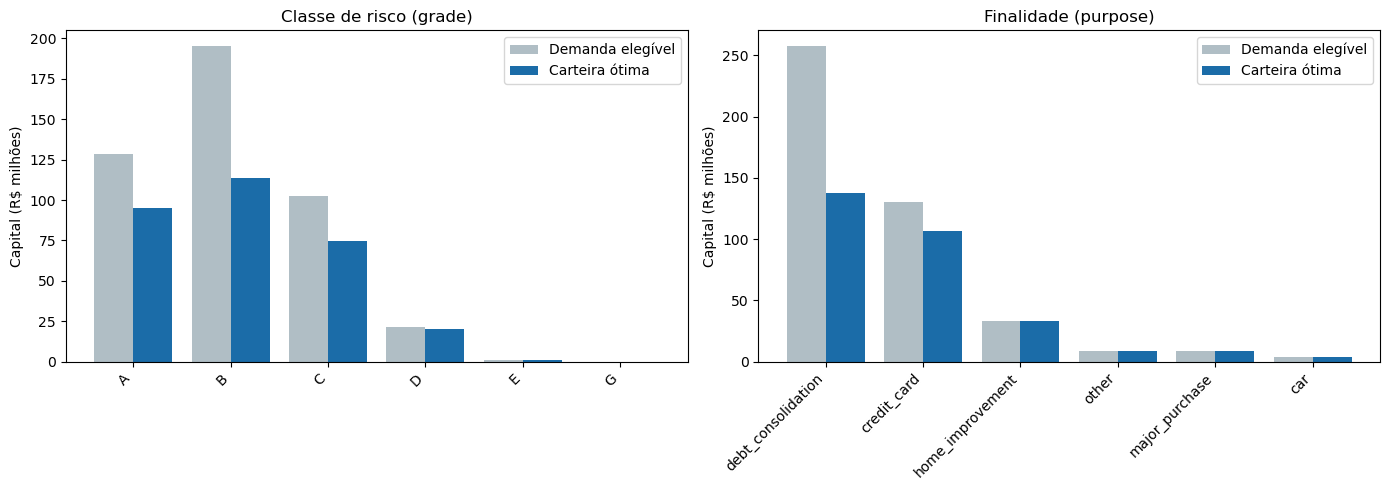

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, dim, titulo in zip(axes, ['grade', 'purpose'], ['Classe de risco (grade)', 'Finalidade (purpose)']):
    dem = clientes.groupby(dim)['loan_amnt'].sum()
    car = carteira.groupby(dim)['loan_amnt'].sum().reindex(dem.index).fillna(0)
    if dim == 'purpose':
        top = dem.sort_values(ascending=False).head(6).index
        dem, car = dem.reindex(top), car.reindex(top)
    pos = np.arange(len(dem)); w = 0.4
    ax.bar(pos - w/2, dem/1e6, w, label='Demanda elegível', color='#B0BEC5')
    ax.bar(pos + w/2, car/1e6, w, label='Carteira ótima', color='#1B6CA8')
    ax.set_xticks(pos); ax.set_xticklabels(dem.index, rotation=45, ha='right')
    ax.set_title(titulo); ax.set_ylabel('Capital (R$ milhões)'); ax.legend()
plt.tight_layout(); plt.show()

# 11. EXPORTAÇÃO DA CARTEIRA SELECIONADA

Por fim, exportamos a carteira ótima com os campos relevantes para registro e auditoria da decisão: o identificador do contrato, suas condições, o risco estimado e a contribuição esperada ao resultado.

In [29]:
cols = ['id_cliente', 'loan_amnt', 'int_rate', 'term', 'grade', 'purpose',
        'PD', 'score', 'juros', 'lucro_esp']
carteira_final = carteira[cols].sort_values('lucro_esp', ascending=False).reset_index(drop=True)
carteira_final.to_parquet('dados/carteira_otima.parquet')
print(f'Carteira ótima exportada: {len(carteira_final):,} contratos.')
carteira_final.head(10)

Carteira ótima exportada: 21,847 contratos.


,id_cliente,loan_amnt,int_rate,term,grade,purpose,PD,score,juros,lucro_esp
0,250586,35000,22.90,60,E,home_improvement,0.19,494.91,"24,079.60","12,930.85"
1,261426,35000,22.40,60,E,debt_consolidation,0.19,495.02,"23,478.40","12,459.94"
2,264932,35000,19.47,60,D,credit_card,0.14,514.81,"20,020.00","12,236.49"
3,289167,35000,18.92,60,D,home_improvement,0.13,519.09,"19,382.80","12,166.88"
4,290582,35000,21.99,60,E,home_improvement,0.20,492.02,"22,988.20","11,594.17"
5,376109,35000,22.15,60,E,debt_consolidation,0.20,491.03,"23,179.00","11,589.16"
6,247464,35000,21.48,60,E,major_purchase,0.19,494.86,"22,381.00","11,545.41"
7,291503,35000,18.92,60,D,major_purchase,0.15,510.95,"19,382.80","11,237.89"
8,363926,35000,20.99,60,E,car,0.19,494.29,"21,800.80","10,987.97"
9,419912,35000,20.99,60,E,major_purchase,0.19,493.67,"21,800.80","10,893.97"


# 12. CONCLUSÃO

A etapa de otimização completa o pipeline *predict-then-optimize*. A partir das probabilidades de default estimadas pelo scorecard, formulamos e resolvemos um programa linear inteiro binário que seleciona, entre os 33.332 contratos elegíveis, a carteira de maior lucro esperado sujeita a limites de capital e de concentração por finalidade.

O resultado não é apenas uma lista de empréstimos aprovados, mas uma política de concessão transparente e auditável: cada decisão decorre de um critério explícito de otimização, e a análise das restrições ativas e do preço-sombra do capital revela à gestão onde está o verdadeiro gargalo — aqui, a diversificação por finalidade, e não o capital. A comparação com políticas ingênuas é o ponto mais instrutivo: elas chegam a exibir lucro bruto maior, mas apenas violando os limites de concentração que a otimização respeita, e o modelo quantifica em reais o custo de manter a carteira diversificada. É essa combinação de decisão ótima, leitura dos gargalos e mensuração de trade-offs que justifica tratar a concessão como um problema de Pesquisa Operacional.